## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI
Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.


**Declaration:** I completed this version without generative AI.

**Student(s):** Claire Curzan

**Date:** 10/14/2026

In [19]:
# Your Phase 1 solution to the problem goes here.

# 1.1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

def createData(noise,N=50):
    np.random.seed(100)
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

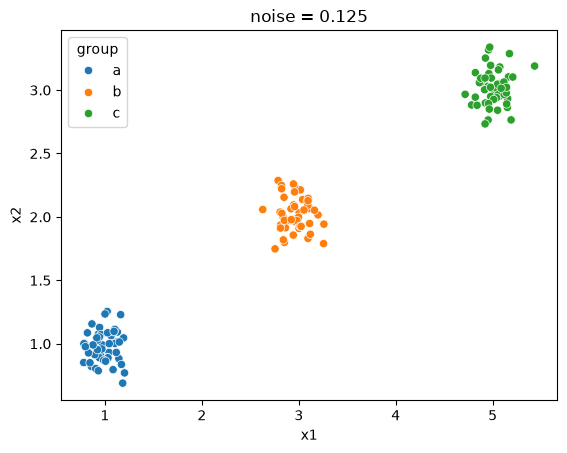

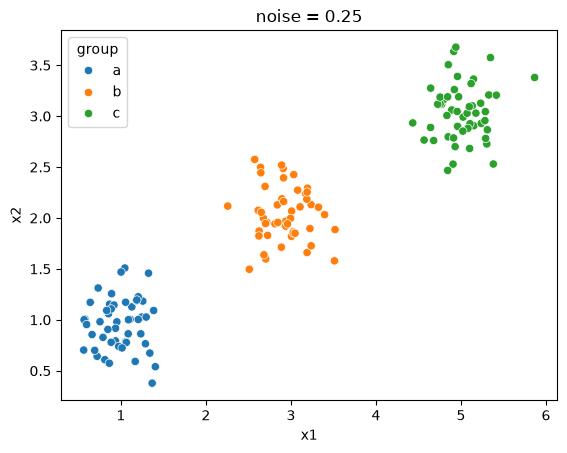

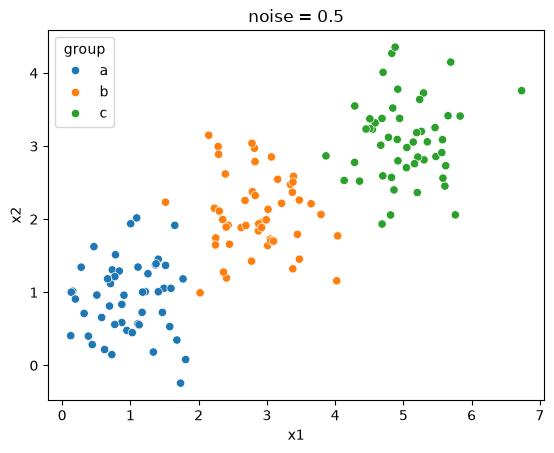

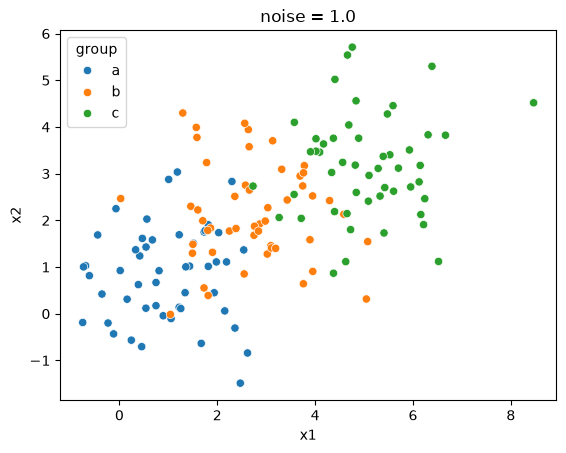

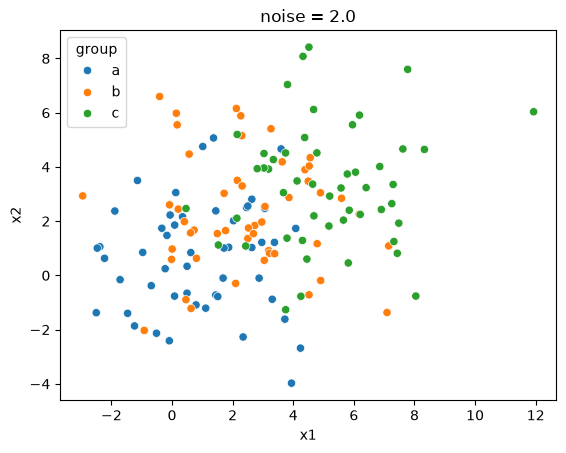

In [20]:
# 1.2
sns.scatterplot(data=df0_125, x='x1', y='x2', hue='group')
plt.title('noise = 0.125')
plt.show()

sns.scatterplot(data=df0_25, x='x1', y='x2', hue='group')
plt.title('noise = 0.25')
plt.show()

sns.scatterplot(data=df0_5, x='x1', y='x2', hue='group')
plt.title('noise = 0.5')
plt.show()

sns.scatterplot(data=df1_0, x='x1', y='x2', hue='group')
plt.title('noise = 1.0')
plt.show()

sns.scatterplot(data=df2_0, x='x1', y='x2', hue='group')
plt.title('noise = 2.0')
plt.show()

1.2) As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?

As the noise goes up, the clusters become visually less distinct:
- In the 0.125 and 0.25 graphs: you can easily see three tight, clearly distinct and separated groups.
- In the 0.5 graph: the groups are still visible, but their edges almost touch.
- In the 1.0 graph: the groups overlap a lot. You can only tell them apart because of the colors.
- In the 2.0 graph: it looks like one diffused cloud. Without colors you wouldn’t be able to see the three distinct groups. 

noise 0.125
[511.61182887933353, 128.88679026320776, 4.913218522689869, 4.333632123942273, 3.801710426325151, 3.2317743734309716, 2.7862863238001077, 2.418796171057092, 2.0580344389455134, 1.9095969253114886]
noise 0.25
[533.2520989126166, 142.72051944214195, 19.65287409075948, 17.334528495769106, 15.242480060502082, 13.04296061884919, 11.492937077498581, 9.717840559878738, 8.349948635008449, 7.467156811989678]
noise 0.5
[606.6179624410297, 186.78123488261386, 77.81737826423296, 67.19255214060917, 58.74410512703274, 50.45113823597723, 42.96053286474463, 36.957074387791494, 32.81057778773023, 29.645666914643492]
noise 1.0
[873.690983345247, 361.58808988521815, 254.9143472762861, 212.6463018014093, 175.46885266667283, 146.9997872356693, 123.19430079560455, 106.02427211810472, 94.74448793661452, 82.94678587787095]
noise 2.0
[1889.202200543243, 1071.8122778851587, 792.2717571884424, 591.1790351714867, 501.87655185864, 418.35461491555685, 353.84378910402387, 303.451774771849, 264.4180198152

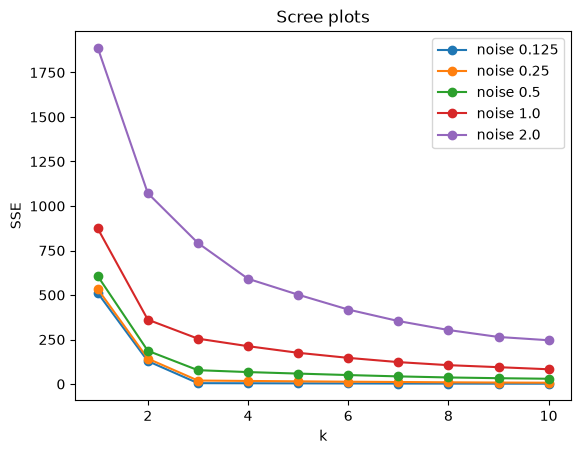

In [21]:
# 1.3
datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
names = ['0.125', '0.25', '0.5', '1.0', '2.0']

for i in range(len(datasets)):
    df = datasets[i]
    X = df[['x1', 'x2']]

    sse_list = []
    k_list = []
    for k in range(1, 11):
        model = KMeans(n_clusters=k, n_init=10, random_state=0)
        model.fit(X)
        sse_list.append(model.inertia_)
        k_list.append(k)

    print('noise', names[i])
    print(sse_list)

    # put all the lines on the same plot so the y axis is the same
    plt.plot(k_list, sse_list, marker='o', label='noise ' + names[i])

plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Scree plots')
plt.legend()
plt.show()

1.3) Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)

Because I put all five scree curves on the same plot, the y-axis is the same for all of them. SSE gets much bigger as noise increases (at k = 1 it goes from about 512 at noise 0.125 to about 1889 at noise 2.0). By putting them all on the same axis, I can see that the low-noise curves fall almost to zero by k = 3 and flatten out, which is a big difference from the high-noise curves that stay high and keep falling steadily.

Low noise (0.125 and 0.25): there’s a very clear elbow at k = 3. SSE drops by about 124 going from 2 to 3 clusters, but only by about 0.6 for the 0.125 graph (or 2.3 for the 0.25 graph) going from 3 to 4. After k = 3 the curve is basically flat, so it’s easy to definitiely pick k = 3.

Medium noise (0.5): the elbow at k = 3 is still visible, but the drop after it (about 10.6) isn’t tiny like in the low noise graphs, so the curve keeps sloping down. I would still pick k = 3, but with less confidence.

High noise (1.0 and 2.0): the elbow mostly disappears. At noise 1.0 the bend is soft, and k = 2, 3 or 4 could all be argued for. At noise 2.0 the drop from 3 to 4 (about 201) is almost as big as the drop from 2 to 3 (about 280), so there’s no point where the reduction becomes “much less.” I wouldn’t be able to definitively select a k. When the groups overlap that much, the data looks like it varies continuously with no distinct groups, so the elbow method doesn’t give a clear choice of k, even though we know there are really three groups.

1.4) Explain the intuition of the elbow, using this numerical simulation as an example.

SSE is the sum of the squared distances from each point to its cluster’s centroid. Adding more clusters lowers SSE most of the time, because each point gets a centroid that’s closer to it. The elbow is the point where adding another cluster stops helping much.

In this simulation there are really 3 groups, centered at (1,1), (3,2) and (5,3). You can think of SSE as kinda having two parts:
- Distance between the real groups: when two real groups are forced into one cluster, their centroid sits in between them and every point is far from it.
- Noise: how spread out the points are around their own group center.

Before k = 3: each new cluster splits apart groups that were lumped together, so SSE drops a lot. For example, with noise 0.125, SSE goes from 511.6 (k = 1) to 128.9 (k = 2) to 4.9 (k = 3). After k = 3: every group already has its own centroid. Extra clusters can only cut a group into smaller pieces, which only reduces the noise a little bit. With noise 0.125, SSE only changes from 4.9 to 4.3 to 3.8. That sudden switch from big drops to tiny drops is what makes the elbow shape at k = 3.

How clear the elbow is depends on how big the noise is compared with the distance between the groups. The group centers are only about 2.2 apart.
- With low noise (0.125, 0.25), the points sit tightly around their centers, so almost all of the SSE comes from the distance between groups. Once k = 3 captures that, there’s almost nothing left, and the elbow is sharp.
- With high noise (2.0), the spread of the points is about as big as the distance between the groups. The groups overlap so much that k-means can’t separate them cleanly, so each extra cluster just cuts the cloud of points into smaller pieces. Each one reduces SSE by a similar amount (about 280, then 201, then 89), and there’s no elbow.

All this is to demonstrate that the elbow shows up when the clusters are well separated compared with how spread out they are, and it disappears as noise increases.

In [22]:
# 2.1
milex = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')
milex = milex[milex['Year'] == 2020]
milex = milex.dropna()
print(milex.shape)
print(milex.dtypes)
print(milex.describe())

(148, 7)
index                               int64
Year                                int64
Country                               str
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object
             index    Year  Spending (2020 USD)  Percent of GDP  \
count   148.000000   148.0           148.000000      148.000000   
mean   2831.256757  2020.0         13153.747670        0.019619   
std    1654.299355     0.0         68005.236120        0.015033   
min      32.000000  2020.0             8.622460        0.000054   
25%    1409.000000  2020.0           204.877177        0.010413   
50%    2871.000000  2020.0           959.535443        0.015324   
75%    4222.500000  2020.0          5289.998320        0.024327   
max    5880.000000  2020.0        778397.200000        0.098470   

       Percent of Government Spending  Spending per Capita  
count             

2.1) Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?

After filtering to 2020 and dropping rows with missing values, there are 148 countries. All four spending columns are already numeric floats, so there’s no need to strip commas or symbols or convert types. I don't think any more data cleaning is needed but there are two things I think would be good to keep in mind while doing the rest of this assignment. There are some potentially redundant columns because the index column is leftover row numbers from the original file, and Year is now 2020 for every row. I kept both in the data frame but left them out of the clustering, since they don’t say anything about spending. (Only the spending variables go into money, burden and all_four.) The “Percent” columns is stored as proportions, not percents (0.037 means 3.7% of GDP and spending appears to be in millions, since the US is 778,397, about $778 billion)

[5.4114144580597685, 2.435270983244869, 1.3218062070200027, 0.629416181260572, 0.4150658555951711, 0.3111621645846242, 0.2121413901992349, 0.14713845174705212, 0.10405086185433807, 0.08599127032390336]


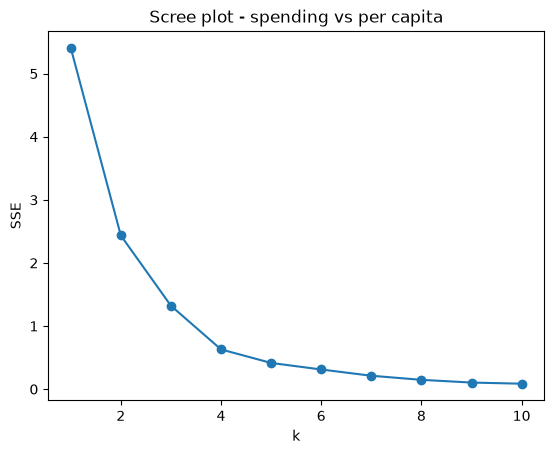

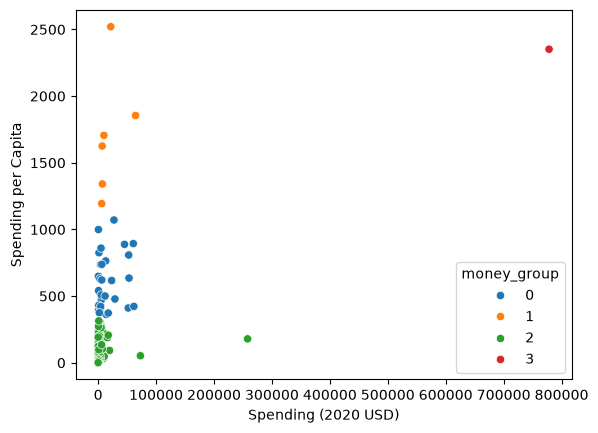

            Spending (2020 USD)                                              \
                          count           mean           std            min   
money_group                                                                   
0                          30.0   17077.591354  20583.053357     405.790494   
1                           6.0   19443.362047  22861.507114    6095.708713   
2                         111.0    4859.185065  25405.739131       8.622460   
3                           1.0  778397.200000           NaN  778397.200000   

                                                                         \
                       25%            50%            75%            max   
money_group                                                               
0              2294.039665    5857.060906   26296.001003   61712.537169   
1              7023.251766    8624.225729   18857.070183   64558.400000   
2               130.010211     382.464677    2297.032353  257973.429834

In [23]:
# 2.2
def maxmin(col):
    return (col - col.min()) / (col.max() - col.min())

money = pd.DataFrame()
money['Spending (2020 USD)'] = maxmin(milex['Spending (2020 USD)'])
money['Spending per Capita'] = maxmin(milex['Spending per Capita'])

# scree plot
money_sse = []
k_values = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=0)
    km.fit(money)
    money_sse.append(km.inertia_)
    k_values.append(k)
print(money_sse)
plt.plot(k_values, money_sse, marker='o')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Scree plot - spending vs per capita')
plt.show()

# k = 4 from the scree plot
km_money = KMeans(n_clusters=4, n_init=10, random_state=0)
km_money.fit(money)
milex['money_group'] = km_money.labels_

sns.scatterplot(data=milex, x='Spending (2020 USD)', y='Spending per Capita', hue='money_group', palette='tab10')
plt.show()

print(milex.groupby('money_group')[['Spending (2020 USD)', 'Spending per Capita']].describe())
print(milex[milex['Country'] == 'United States of America'])

for g in range(4):
    print(g, milex[milex['money_group'] == g]['Country'].tolist())

2.2) Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?

SSE for k = 1 to 10: 5.41, 2.44, 1.32, 0.63, 0.42, 0.31, ... The drops are 2.98, 1.11, 0.69, then only 0.21 from 4 to 5. Adding a group after k = 4 reduces SSE by much less, so I picked k = 4.

From what I can observe, the United States is in a group by itself. It’s so far out on total spending (about $778B) that k-means gives it its own centroid. Looking at the other patterns in the cluster membership, I can see the following groups:
- High per capita, small/medium total (6 countries): Israel, Kuwait, Norway, Oman, Saudi Arabia, Singapore. Mean spending per capita is about $1,700.
- Medium per capita (30 countries): Mostly wealthy European countries like the UK, France, Germany, and also Japan, Australia, Canada, South Korea and Taiwan, and Russia. Per capita is about $360–1,070.
- Low per capita (111 countries): everyone else. Mean per capita is about $80, and the median total is only about $380M.
The groups split almost entirely on spending per capita, with total spending only mattering for the US. China (the second-biggest spender) and India land in the low group because of their huge populations. It appears that the groups line up with how rich a country is.

[6.960939851613136, 2.9274233223534734, 1.9957889632900963, 1.4766908505295684, 1.0827650977184573, 0.803337145210909, 0.6462328095276826, 0.5354367192274307, 0.43763184163169766, 0.38573099588840415]


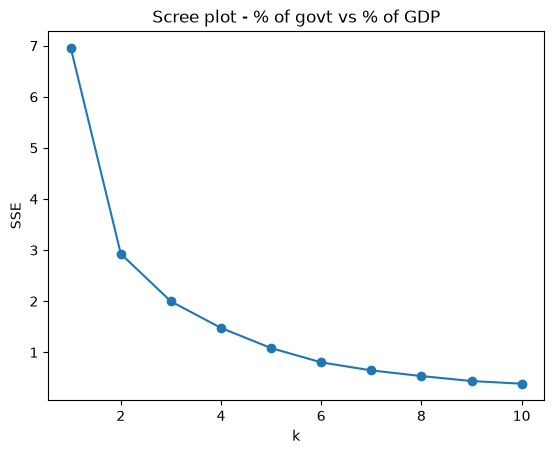

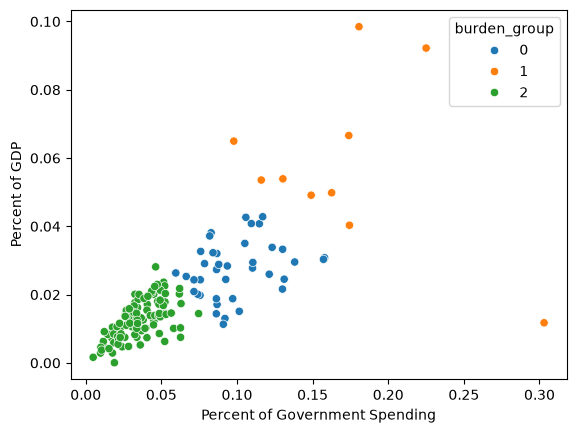

             Percent of Government Spending                                \
                                      count      mean       std       min   
burden_group                                                                
0                                      39.0  0.098683  0.024125  0.059520   
1                                      10.0  0.171289  0.058725  0.097882   
2                                      99.0  0.035777  0.014549  0.004896   

                                                     Percent of GDP            \
                   25%       50%       75%       max          count      mean   
burden_group                                                                    
0             0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1             0.135010  0.168248  0.179081  0.303027           10.0  0.058071   
2             0.025921  0.034261  0.047402  0.074624           99.0  0.012664   

                                                  

In [24]:
# 2.3
burden = pd.DataFrame()
burden['Percent of Government Spending'] = maxmin(milex['Percent of Government Spending'])
burden['Percent of GDP'] = maxmin(milex['Percent of GDP'])

burden_sse = []
k_values = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=0)
    km.fit(burden)
    burden_sse.append(km.inertia_)
    k_values.append(k)
print(burden_sse)
plt.plot(k_values, burden_sse, marker='o')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Scree plot - % of govt vs % of GDP')
plt.show()

# k = 3 from the scree plot
km_burden = KMeans(n_clusters=3, n_init=10, random_state=0)
km_burden.fit(burden)
milex['burden_group'] = km_burden.labels_

sns.scatterplot(data=milex, x='Percent of Government Spending', y='Percent of GDP', hue='burden_group', palette='tab10')
plt.show()

print(milex.groupby('burden_group')[['Percent of Government Spending', 'Percent of GDP']].describe())
print(milex[milex['Country'] == 'United States of America'])

for g in range(3):
    print(g, milex[milex['burden_group'] == g]['Country'].tolist())

2.3) Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?

SSE: 6.96, 2.93, 2.00, 1.48, 1.08, ... The big drop is from 1 to 2 (about 4.0), then 0.93, 0.52, 0.39, and so on. The elbow is softer here, closer to the “No Clear Elbow” case from the slides. I picked k = 3.

- Low burden (99 countries): on average about 1.3% of GDP and 3.6% of government spending. This includes most of Europe, plus Canada, Australia, China, Brazil and Japan.
- Medium burden (39 countries): about 2.7% of GDP and 10% of government spending. The United States is in this group, with India, Russia, Turkey, South Korea, Iran, Colombia and several African countries.
- High burden (10 countries): about 5.8% of GDP and 17% of government spending: Algeria, Armenia, Azerbaijan, Belarus, Israel, Jordan, Kuwait, Oman, Pakistan, Saudi Arabia.

Compared to part 2, these groups are very different. Part 2 sorted countries by how much money they spend, which mostly tracks wealth. Part 3 sorts them by how big a priority the military is relative to their economy and budget. The US goes from an extreme outlier to just a “medium” country, and rich European countries that looked big in part 2 end up in the low group. The high-burden group is mostly countries that are in tense/high conflict regions (for example: some countries in the Middle East like Israel and Jordan).

[12.372354309672904, 7.710184028790121, 5.192636599582205, 4.20699438192927, 3.258183413893874, 2.6862202571139213, 2.2510905916330564, 1.888594694547372, 1.6130037530999561, 1.4535550495532987]


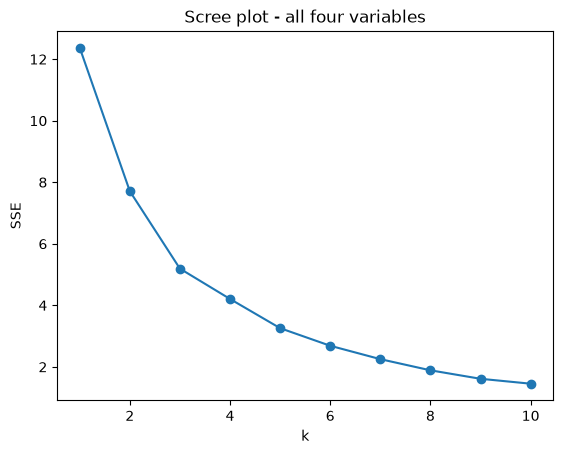

          Spending (2020 USD)                                             \
                        count           mean            std          min   
all_group                                                                  
0                        86.0    4513.543790   27841.230783     8.622460   
1                         6.0  147964.582042  309635.189564  6095.708713   
2                        30.0    9073.543709   18135.032885   163.926877   
3                        26.0   15330.618681   18923.469359   405.790494   

                                                                   \
                   25%           50%           75%            max   
all_group                                                           
0            81.022976    288.061512   1138.618231  257973.429834   
1          7700.424616  15897.570598  53872.942442  778397.200000   
2           522.737081   1663.090134   8646.648849   72937.064048   
3          3176.345598   5857.060906  21818.934764   

In [25]:
# 2.4
all_four = pd.DataFrame()
all_four['Spending (2020 USD)'] = maxmin(milex['Spending (2020 USD)'])
all_four['Spending per Capita'] = maxmin(milex['Spending per Capita'])
all_four['Percent of Government Spending'] = maxmin(milex['Percent of Government Spending'])
all_four['Percent of GDP'] = maxmin(milex['Percent of GDP'])

all_sse = []
k_values = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=0)
    km.fit(all_four)
    all_sse.append(km.inertia_)
    k_values.append(k)
print(all_sse)
plt.plot(k_values, all_sse, marker='o')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Scree plot - all four variables')
plt.show()

# k = 4 from the scree plot
km_all = KMeans(n_clusters=4, n_init=10, random_state=0)
km_all.fit(all_four)
milex['all_group'] = km_all.labels_

print(milex.groupby('all_group')[['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']].describe())

for g in range(4):
    print(g, milex[milex['all_group'] == g]['Country'].tolist())

2.4) Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?

SSE: 12.37, 7.71, 5.19, 4.21, 3.26, 2.69, ... The drops are 4.66, 2.52, 0.99, 0.95, 0.57, so the elbow is around k = 4 (but it’s not very sharp).

- Rich and high-burden (6 countries): the US, Israel, Kuwait, Oman, Saudi Arabia, Singapore.
- Wealthy, low-burden (26 countries): mostly Europe/NATO plus Japan, Australia, New Zealand and Canada.
- Lower-income, high-burden (30 countries): Russia, India, Pakistan, Iran, South Korea, Taiwan, Ukraine, Algeria and others.
- Low on everything (86 countries): including China.

The results from this part look like a combination of the previous two parts. The per capita variable separates rich from poor countries, like in part 2. The percent variables separate high-burden from low-burden countries, like in part 3. The US is no longer alone, because the percent variables pull it toward Israel and the Gulf states. The elbow is less clear than in part 2, but I’d say the result from this part is the most informative of the three.

2.5) Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

I think the k-MC did find a lot of useful patterns for me in analyzing the spending. The biggest patterns I saw were that the US is an outlier for total spending, the countries in conflict/tense hot spots spend a huge share of their economy and budget on the military, and big countries like China and India look “low” when you look at spending per person, even though they’re the 2nd and 3rd biggest spenders in total, because their huge populations make the per capita amount small.

Some other patterns I noticed were that Israel and the Gulf states (Saudi Arabia, Kuwait, Oman) plus Singapore stayed grouped together in parts 2 and 4 because they're both rich and high-burden, which made them the most consistent group across the different variable choices. Also, some poorer countries like Mali, Chad and Uganda ended up in a high-burden group with Russia, India and Pakistan in part 4, since they don't spend much in dollars but the military is a big part of their economy or budget. It was also interesting to see which countries switched groups. The US was alone in part 2 but joined Israel and the Gulf states in part 4, and Russia went from "medium per capita" in part 2 to "high burden" in part 4. This showed me that the spending variables mostly measure how big or rich a country is, while the percent variables measure how much of a priority the military is.

I do think though that any results I gleaned depend a lot on which variables I chose (parts 2, 3 and 4 gave very different groupings). k-means as an analysis tool is "greedy" and might not find the best clusters, so it's important to choose k based on how the clusters will be used.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [26]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]